In [ ]:
from google.colab import files
uploaded = files.upload()


Saving video games sales (1).csv to video games sales (1).csv


In [ ]:
import pandas as pd

df = pd.read_csv('video games sales (1).csv')
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [ ]:
gta_games = df[df['Name'].str.contains('Grand Theft Auto', na=False)]
print(gta_games[['Name', 'Year', 'Platform', 'Global_Sales']])

                                                    Name    Year Platform  \
16                                    Grand Theft Auto V  2013.0      PS3   
17                         Grand Theft Auto: San Andreas  2004.0      PS2   
23                                    Grand Theft Auto V  2013.0     X360   
24                           Grand Theft Auto: Vice City  2002.0      PS2   
38                                  Grand Theft Auto III  2001.0      PS2   
44                                    Grand Theft Auto V  2014.0      PS4   
51                                   Grand Theft Auto IV  2008.0     X360   
56                                   Grand Theft Auto IV  2008.0      PS3   
90                Grand Theft Auto: Liberty City Stories  2005.0      PSP   
197                                   Grand Theft Auto V  2014.0     XOne   
198                  Grand Theft Auto: Vice City Stories  2006.0      PSP   
360               Grand Theft Auto: Liberty City Stories  2006.0      PS2   

In [ ]:
gta_total = gta_games.groupby('Name')['Global_Sales'].sum().sort_values(ascending=False)
print(gta_total)

Name
Grand Theft Auto V                                                               55.92
Grand Theft Auto: San Andreas                                                    23.86
Grand Theft Auto IV                                                              22.47
Grand Theft Auto: Vice City                                                      16.19
Grand Theft Auto III                                                             13.11
Grand Theft Auto: Liberty City Stories                                           11.26
Grand Theft Auto: Vice City Stories                                               6.05
Rockstar Games Double Pack: Grand Theft Auto III & Grand Theft Auto Vice City     4.21
Grand Theft Auto 2                                                                3.42
Grand Theft Auto                                                                  2.56
Grand Theft Auto: Chinatown Wars                                                  2.43
Grand Theft Auto: Mission Pack #1, Lon

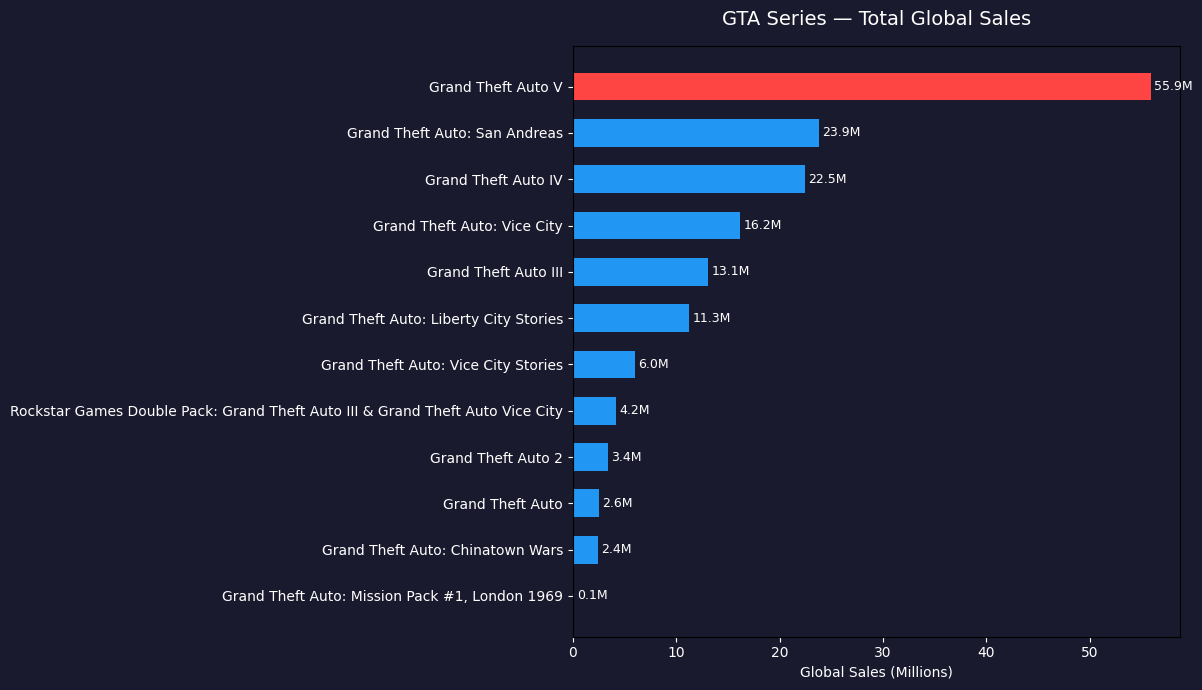

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(12, 7))

colors = ['#FF4444' if name == 'Grand Theft Auto V' else '#2196F3'
          for name in gta_total.sort_values().index]
bars = ax.barh(gta_total.sort_values().index,
               gta_total.sort_values().values,
               color=colors, edgecolor='none', height=0.6)

for bar, value in zip(bars, gta_total.sort_values().values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{value:.1f}M', va='center', fontsize=9, color='white')

ax.set_facecolor('#1a1a2e')
fig.patch.set_facecolor('#1a1a2e')
ax.tick_params(colors='white')
ax.xaxis.label.set_color('white')
ax.title.set_color('white')
plt.title('GTA Series — Total Global Sales', fontsize=14, pad=15)
plt.xlabel('Global Sales (Millions)')
plt.tight_layout()
plt.show()

In [ ]:
plt.savefig('gta_sales_chart.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')

NameError: name 'plt' is not defined

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving video games sales (1).csv to video games sales (1).csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('video games sales (1).csv')
gta_games = df[df['Name'].str.contains('Grand Theft Auto', na=False)]
gta_total = gta_games.groupby('Name')['Global_Sales'].sum().sort_values(ascending=False)
print(gta_total)


Name
Grand Theft Auto V                                                               55.92
Grand Theft Auto: San Andreas                                                    23.86
Grand Theft Auto IV                                                              22.47
Grand Theft Auto: Vice City                                                      16.19
Grand Theft Auto III                                                             13.11
Grand Theft Auto: Liberty City Stories                                           11.26
Grand Theft Auto: Vice City Stories                                               6.05
Rockstar Games Double Pack: Grand Theft Auto III & Grand Theft Auto Vice City     4.21
Grand Theft Auto 2                                                                3.42
Grand Theft Auto                                                                  2.56
Grand Theft Auto: Chinatown Wars                                                  2.43
Grand Theft Auto: Mission Pack #1, Lon

/tmp/ipykernel_522/1761329352.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  gta_regional = gta_regional[gta_total >= 5]


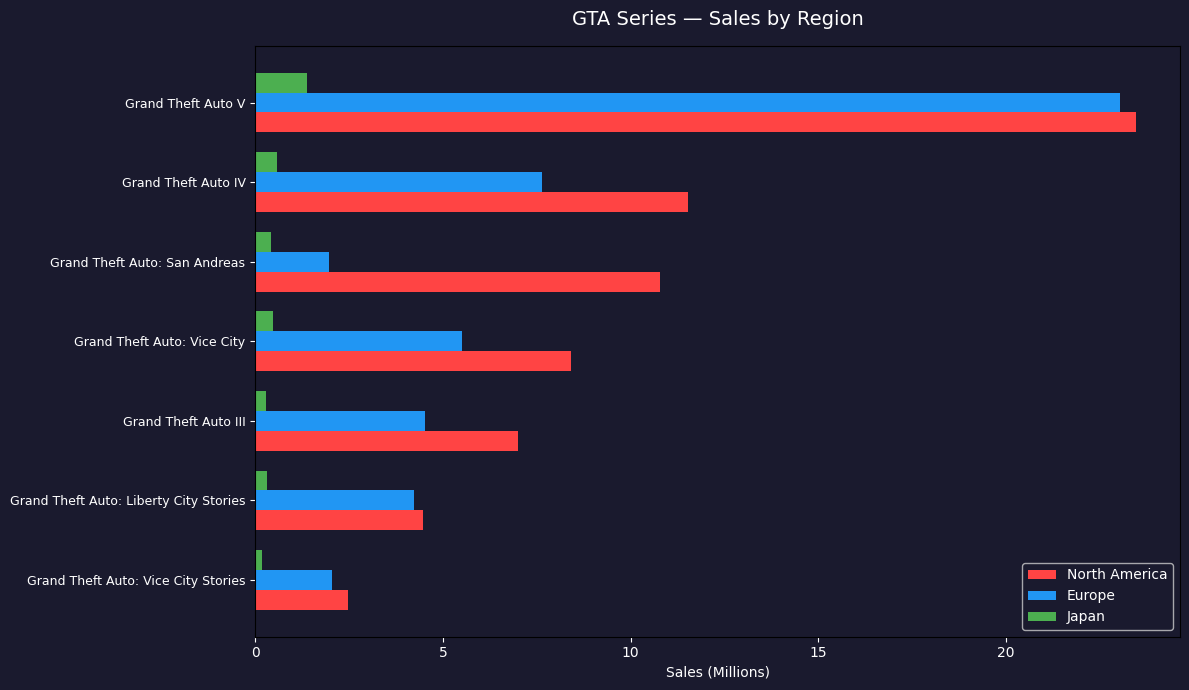

In [ ]:
gta_regional = gta_games.groupby('Name')[['NA_Sales','EU_Sales','JP_Sales']].sum()
gta_regional = gta_regional[gta_total >= 5]
gta_regional = gta_regional.sort_values('NA_Sales')
fig, ax = plt.subplots(figsize=(12, 7))

bar_width = 0.25
import numpy as np
x = np.arange(len(gta_regional))
ax.barh(x - bar_width, gta_regional['NA_Sales'], bar_width, label='North America', color='#FF4444')
ax.barh(x, gta_regional['EU_Sales'], bar_width, label='Europe', color='#2196F3')
ax.barh(x + bar_width, gta_regional['JP_Sales'], bar_width, label='Japan', color='#4CAF50')

ax.set_yticks(x)
ax.set_yticklabels(gta_regional.index, fontsize=9)
ax.set_facecolor('#1a1a2e')
fig.patch.set_facecolor('#1a1a2e')
ax.tick_params(colors='white')
ax.xaxis.label.set_color('white')
ax.title.set_color('white')
ax.legend(facecolor='#1a1a2e', labelcolor='white')
plt.title('GTA Series — Sales by Region', fontsize=14, pad=15)
plt.xlabel('Sales (Millions)')
plt.tight_layout()
plt.show()


In [ ]:
plt.savefig('gta_regional_chart.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.savefig('gta_regional_chart.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')

<Figure size 640x480 with 0 Axes>

In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Main GTA games with their release years and sales
years = np.array([2001, 2004, 2008, 2013]).reshape(-1, 1)
sales = np.array([13.11, 23.86, 22.47, 55.92])

# Train the model
model = LinearRegression()
model.fit(years, sales)

# Predict GTA 6 (2026)
gta6_year = np.array([[2026]])
gta6_prediction = model.predict(gta6_year)[0]

print(f"Predicted GTA 6 sales: {gta6_prediction:.1f} million copies")

Predicted GTA 6 sales: 92.7 million copies


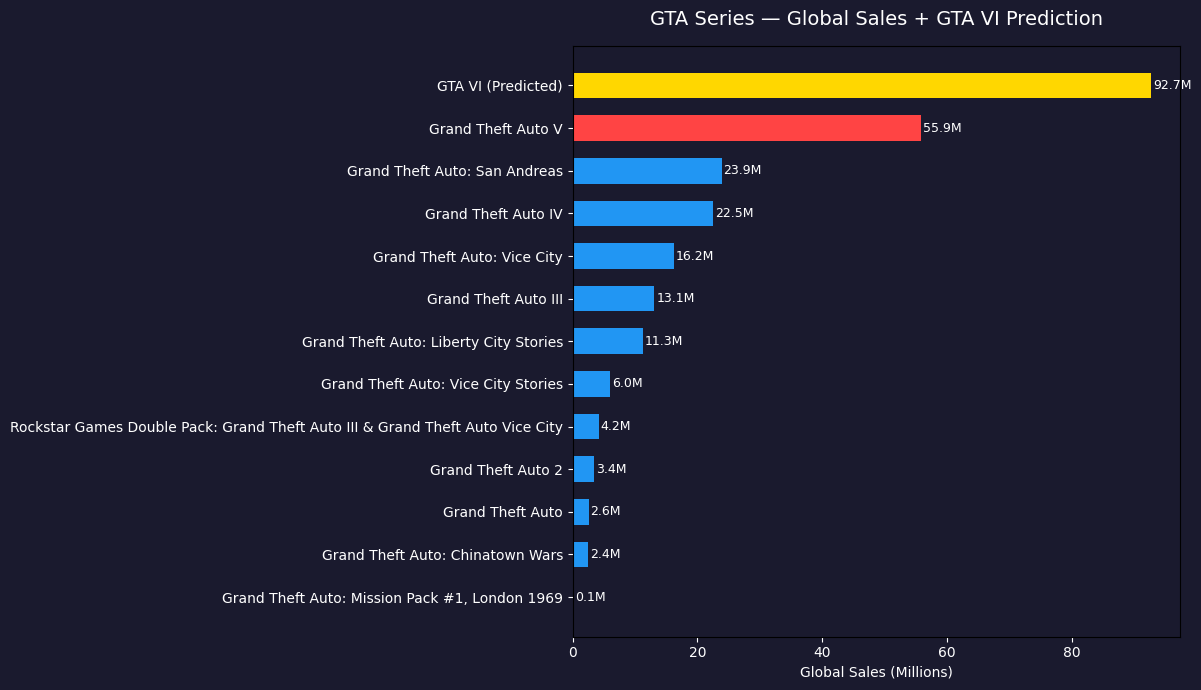

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))

games = list(gta_total.sort_values().index) + ['GTA VI (Predicted)']
values = list(gta_total.sort_values().values) + [gta6_prediction]

colors = ['#FF4444' if name == 'Grand Theft Auto V'
          else '#FFD700' if name == 'GTA VI (Predicted)'
          else '#2196F3'
          for name in games]

bars = ax.barh(games, values, color=colors, edgecolor='none', height=0.6)

for bar, value in zip(bars, values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{value:.1f}M', va='center', fontsize=9, color='white')

ax.set_facecolor('#1a1a2e')
fig.patch.set_facecolor('#1a1a2e')
ax.tick_params(colors='white')
ax.xaxis.label.set_color('white')
ax.title.set_color('white')
plt.title('GTA Series — Global Sales + GTA VI Prediction', fontsize=14, pad=15)
plt.xlabel('Global Sales (Millions)')
plt.tight_layout()
plt.show()

In [ ]:
plt.savefig('gta_prediction_chart.png', dpi=150, bbox_inches='tight', facecolor='#1a1a2e')


<Figure size 640x480 with 0 Axes>